In [3]:
# Locate the repository root (works regardless of the launch directory) and expose it on sys.path.
import os, sys
_p = os.path.abspath(os.getcwd())
while _p != os.path.dirname(_p) and not os.path.exists(os.path.join(_p, 'src', 'config.py')):
    _p = os.path.dirname(_p)
BASE = _p
sys.path.insert(0, BASE)
sys.path.insert(0, os.path.join(BASE, 'ana'))
from src.config import BIOMEDBERT


# PromptCASL - Results Figures


In [ ]:


import os, glob, csv
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import defaultdict
from scipy.stats import wilcoxon

CELL_LINES = ['A549', 'PK1', 'IPC298', 'MEWO', 'GI1', 'HS936T']
FOLDS_DIR = f'{BASE}/data/folds_assignment'

def _find(root, sub):
    g = [d for d in glob.glob(f'{root}/*') if sub in os.path.basename(d) and os.path.isdir(d)]
    return g[0] if g else None

# blind (A1): no-context baseline
A1_GPLO = f'{BASE}/results/ablation_eval/20260629_173633_pair_pathway_evidence_reactome_K16_gplo_ppe_K16_A1_nocontext'
GROOT = f'{BASE}/results/ablation_eval_gplo_pk1fix'
GDIR = {'full': _find(GROOT, 'gplo_ppe_K16_pk1fix'), 'B1': _find(GROOT, 'B1_noomics_pk1fix'),
        'C1': _find(GROOT, 'C1_randgenept_pk1fix'), 'D1': _find(GROOT, 'D1_frozenllm_pk1fix'), 'A1': A1_GPLO}

def load_subset(d):
    return {r['subset']: (float(r['AUC']), float(r['AUPR'])) for r in csv.DictReader(open(f'{d}/metrics_subset.csv'))}
GSUB = {k: load_subset(v) for k, v in GDIR.items()}

# ── pair labels: conflict = spans >=2 cells with BOTH labels; consistent = >=2 cells SAME label ──
def _np(gp): return '|'.join(sorted(str(gp).split('|')))
_pcl = defaultdict(dict)
for cl in CELL_LINES:
    _df = pd.read_csv(f'{FOLDS_DIR}/{cl}_filtered_NP1_F.csv')
    for g1, g2, y in zip(_df.gene_1, _df.gene_2, _df.SL_or_not):
        _pcl[_np(f'{g1}|{g2}')][cl] = int(y == 'SL')
CONF = {p for p, l in _pcl.items() if len(l) >= 2 and len(set(l.values())) > 1}
CONS = {p for p, l in _pcl.items() if len(l) >= 2 and len(set(l.values())) == 1}

# ── Route A: within-pair direction consistency (recomputed from test_predictions) ──
def route_a(dirs):
    a1 = pd.read_csv(f"{dirs['A1']}/test_predictions.csv"); a1['np'] = a1.gene_pair.map(_np)
    d = a1[a1.np.isin(CONF)]
    clean = sorted([p for p, g in d.groupby('np') if g.fold.nunique() == 1 and set(g.label) == {0, 1}])
    WIN, MARG = {}, {}
    for k, dd in dirs.items():
        p = pd.read_csv(f"{dd}/test_predictions.csv"); p['np'] = p.gene_pair.map(_np)
        c = p[p.np.isin(clean)]; win, marg = {}, {}
        for pair, g in c.groupby('np'):
            sl = g.loc[g.label == 1, 'prob'].values; ns = g.loc[g.label == 0, 'prob'].values
            w = sum(a > b for a in sl for b in ns); t = sum(a == b for a in sl for b in ns)
            l = len(sl) * len(ns) - w - t
            win[pair] = (w + 0.5 * t) / (w + t + l); marg[pair] = sl.mean() - ns.mean()
        WIN[k] = np.array([win[p] for p in clean]); MARG[k] = np.array([marg[p] for p in clean])
    return WIN, MARG, len(clean)
GWIN, GMARG, GN = route_a(GDIR)

# ── per-pair SPREAD = max-min predicted prob over the cell lines a pair appears in (blind vs full) ──
def per_pair_spread(pred_csv, pairs):
    df = pd.read_csv(pred_csv); df['np'] = df.gene_pair.map(_np); df = df[df.np.isin(pairs)]
    out = {}
    for p, g in df.groupby('np'):
        pr = g.groupby('cell_line')['prob'].mean()
        if len(pr) >= 2:
            out[p] = float(pr.max() - pr.min())
    return out
cf_nc = per_pair_spread(f"{GDIR['A1']}/test_predictions.csv", CONF)    # conflict,   blind
cf_fl = per_pair_spread(f"{GDIR['full']}/test_predictions.csv", CONF)  # conflict,   full
ck_nc = per_pair_spread(f"{GDIR['A1']}/test_predictions.csv", CONS)    # consistent, blind
ck_fl = per_pair_spread(f"{GDIR['full']}/test_predictions.csv", CONS)  # consistent, full
cc = sorted(set(cf_nc) & set(cf_fl)); kk = sorted(set(ck_nc) & set(ck_fl))
a = np.array([cf_nc[p] for p in cc]); b = np.array([cf_fl[p] for p in cc])
pval = wilcoxon(b, a).pvalue

# shared labels / colors for the figure cells below
LAB = {'A1': 'blind\n(A1)', 'C1': 'rand-\ngenePT', 'D1': 'frozen\nLLM', 'B1': 'no-\nomics',
       'full': 'full\n(PPE)'}
COL = {'A1': '#bdbdbd', 'C1': '#fdae61', 'D1': '#f46d43', 'B1': '#fb9a99',
       'full': '#d62728'}
print(f'GPLO route-A clean pairs n={GN}; conflict spread pairs n={len(cc)}, consistent n={len(kk)}')
print('GPLO conflict_B:', {k: round(GSUB[k]["conflict_B"][0], 3) for k in GSUB})
print(f'conflict spread: blind {a.mean():.3f} -> full {b.mean():.3f} ({(b>a).mean():.0%} up, p={pval:.1e})')


In [1]:
# Figure 5 display labels
# LAB maps each rung code to the display label used by all Figure-5 panels.



LAB = {                       # rung code  ->  shown label  (edit the right side)
    'A1':   'blind',    # no-context baseline
    'C1':   'rand-GenePT',  # randomized GenePT
    'D1':   'frozen LLM',    # frozen BiomedBERT
    'B1':   'no-omics',     # no omics / pathway token
    'full': 'full',    # full model
}
print('Figure 5 labels ->', {k: v.replace(chr(10), ' ') for k, v in LAB.items()})

Figure 5 labels -> {'A1': 'blind', 'C1': 'rand-GenePT', 'D1': 'frozen LLM', 'B1': 'no-omics', 'full': 'full'}


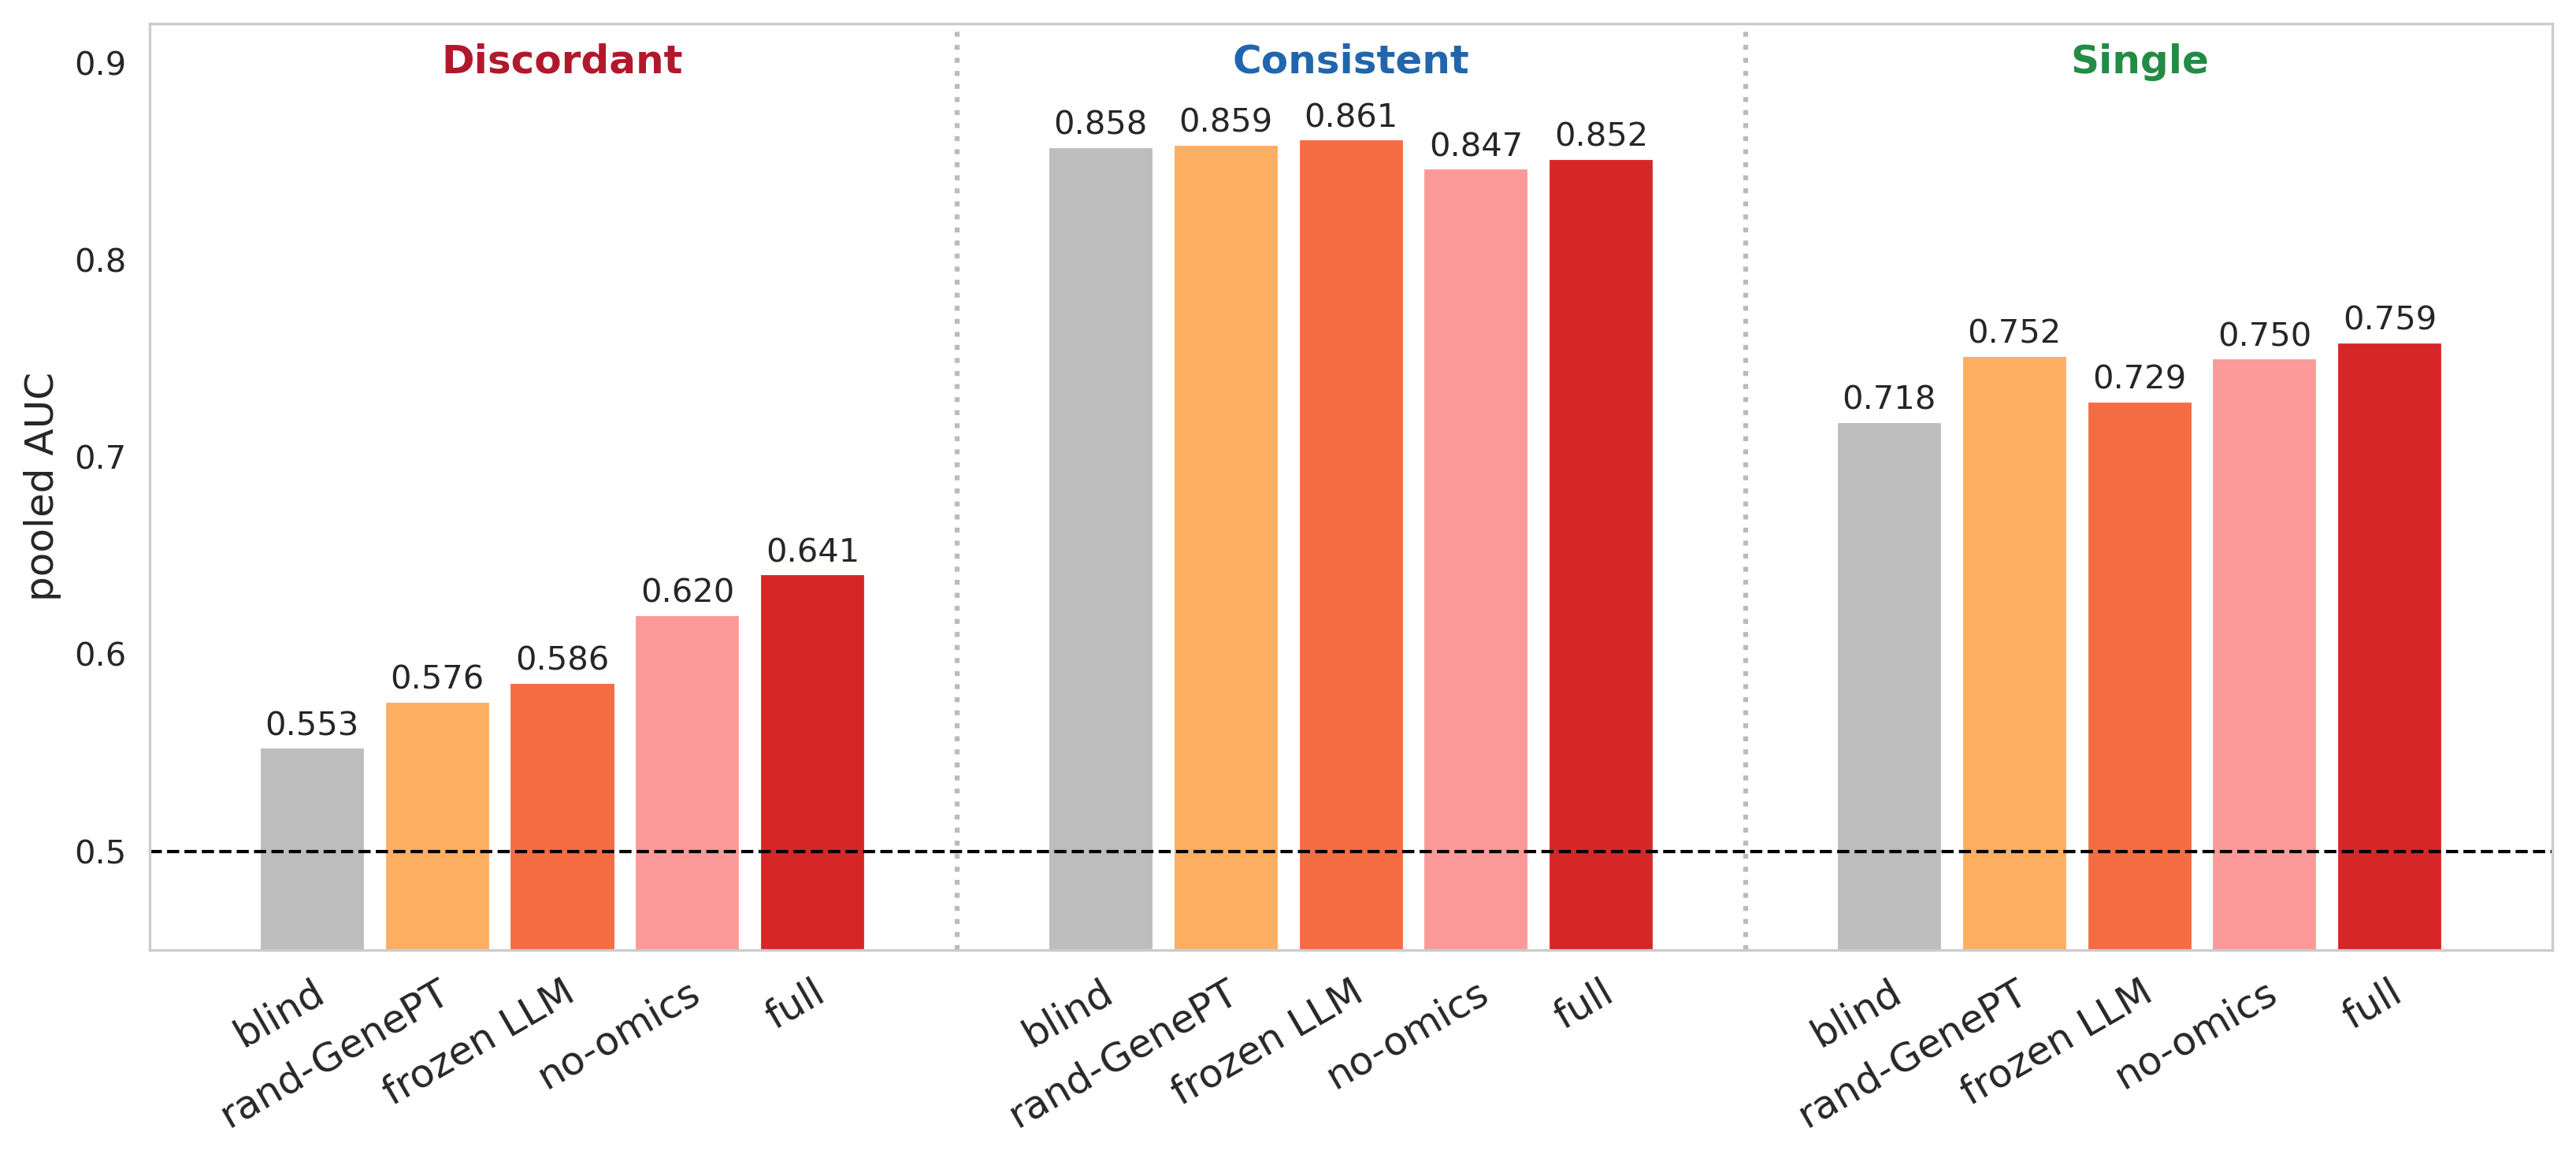

GPLO subset AUC by ablation (PK1-fixed):  conflict_B | consistent_B | single_cl_B
  blind          conflict=0.553  consistent=0.858  single=0.718
  rand-GenePT    conflict=0.576  consistent=0.859  single=0.752
  frozen LLM     conflict=0.586  consistent=0.861  single=0.729
  no-omics       conflict=0.620  consistent=0.847  single=0.750
  full           conflict=0.641  consistent=0.852  single=0.759

SINGLE subset (single_cl_B, n=2003, prevalence=0.272):
  AUC  blind 0.718 -> full 0.759
  AUPR blind 0.498 -> full 0.564  (base = prevalence 0.272)
Note: single-cell-line pairs appear in ONE cell line -> no cross-cell-line spread (single omitted from the spread panel).


In [ ]:


SHOW = ['A1', 'C1', 'D1', 'B1', 'full']
order = [k for k in sorted(GSUB, key=lambda k: GSUB[k]['conflict_B'][0]) if k in SHOW]

# prevalence + n per subset (constant across ablations; read from the full run's metrics_subset.csv)
_ms   = {r['subset']: r for r in csv.DictReader(open(f"{GDIR['full']}/metrics_subset.csv"))}
SUBS  = ['conflict_B', 'consistent_B', 'single_cl_B']
PREV  = {s: float(_ms[s]['prevalence']) for s in SUBS}
N_SUB = {s: int(_ms[s]['n']) for s in SUBS}

# 3-group AUC ladder: CONFLICT | CONSISTENT | SINGLE (bars ordered by conflict_B ascending)
fig, ax = plt.subplots(figsize=(11, 5), dpi=300)
n = len(order); GAP = 1.3
STEP  = 1.0    # in-group bar spacing (larger = wider gap); must exceed BAR_W
BAR_W = 0.85   # bar width
xc = np.arange(n) * STEP
xk = xc + n * STEP + GAP
xs = xk + n * STEP + GAP

    #    ('single_cl_B', xs, 'SINGLE', '#238b45')]
GRP = [('conflict_B', xc, 'Discordant', '#b2182b'), ('consistent_B', xk, 'Consistent', '#2166ac'),
       ('single_cl_B', xs, 'Single', '#238b45')]
for skey, xg, gname, gcol in GRP:
    for i, k in enumerate(order):
        v = GSUB[k][skey][0]
        ax.bar(xg[i], v, 0.85, color=COL[k])
        ax.text(xg[i], v + 0.006, f'{v:.3f}', ha='center', fontsize=10)
    ax.text(xg.mean(), 0.895, gname, ha='center', fontweight='bold', color=gcol, fontsize=12)
ax.axhline(0.5, color='k', ls='--', lw=1); 
ax.grid(False)
ax.axvline((xc[-1] + xk[0]) / 2, color='#bbbbbb', ls=':'); 
ax.axvline((xk[-1] + xs[0]) / 2, color='#bbbbbb', ls=':')
ax.set_xticks(list(xc) + list(xk) + list(xs)); 
ax.set_xticklabels([LAB[k] for k in order] * 3, rotation=30, ha='right',
                   rotation_mode='anchor', fontsize=12)
ax.set_ylim(0.45, 0.92); ax.set_ylabel('pooled AUC',fontsize=12)
plt.tight_layout(); plt.show()

print('GPLO subset AUC by ablation:  conflict_B | consistent_B | single_cl_B')
for k in order:
    print(f'  {LAB[k].replace(chr(10), " "):14s} '
          f'conflict={GSUB[k]["conflict_B"][0]:.3f}  consistent={GSUB[k]["consistent_B"][0]:.3f}  '
          f'single={GSUB[k]["single_cl_B"][0]:.3f}')
print(f"\nSINGLE subset (single_cl_B, n={N_SUB['single_cl_B']}, prevalence={PREV['single_cl_B']:.3f}):")
print(f"  AUC  blind {GSUB['A1']['single_cl_B'][0]:.3f} -> full {GSUB['full']['single_cl_B'][0]:.3f}")
print(f"  AUPR blind {GSUB['A1']['single_cl_B'][1]:.3f} -> full {GSUB['full']['single_cl_B'][1]:.3f}  "
      f"(base = prevalence {PREV['single_cl_B']:.3f})")
    
print('Note: single-cell-line pairs appear in ONE cell line -> no cross-cell-line spread (single omitted from the spread panel).')

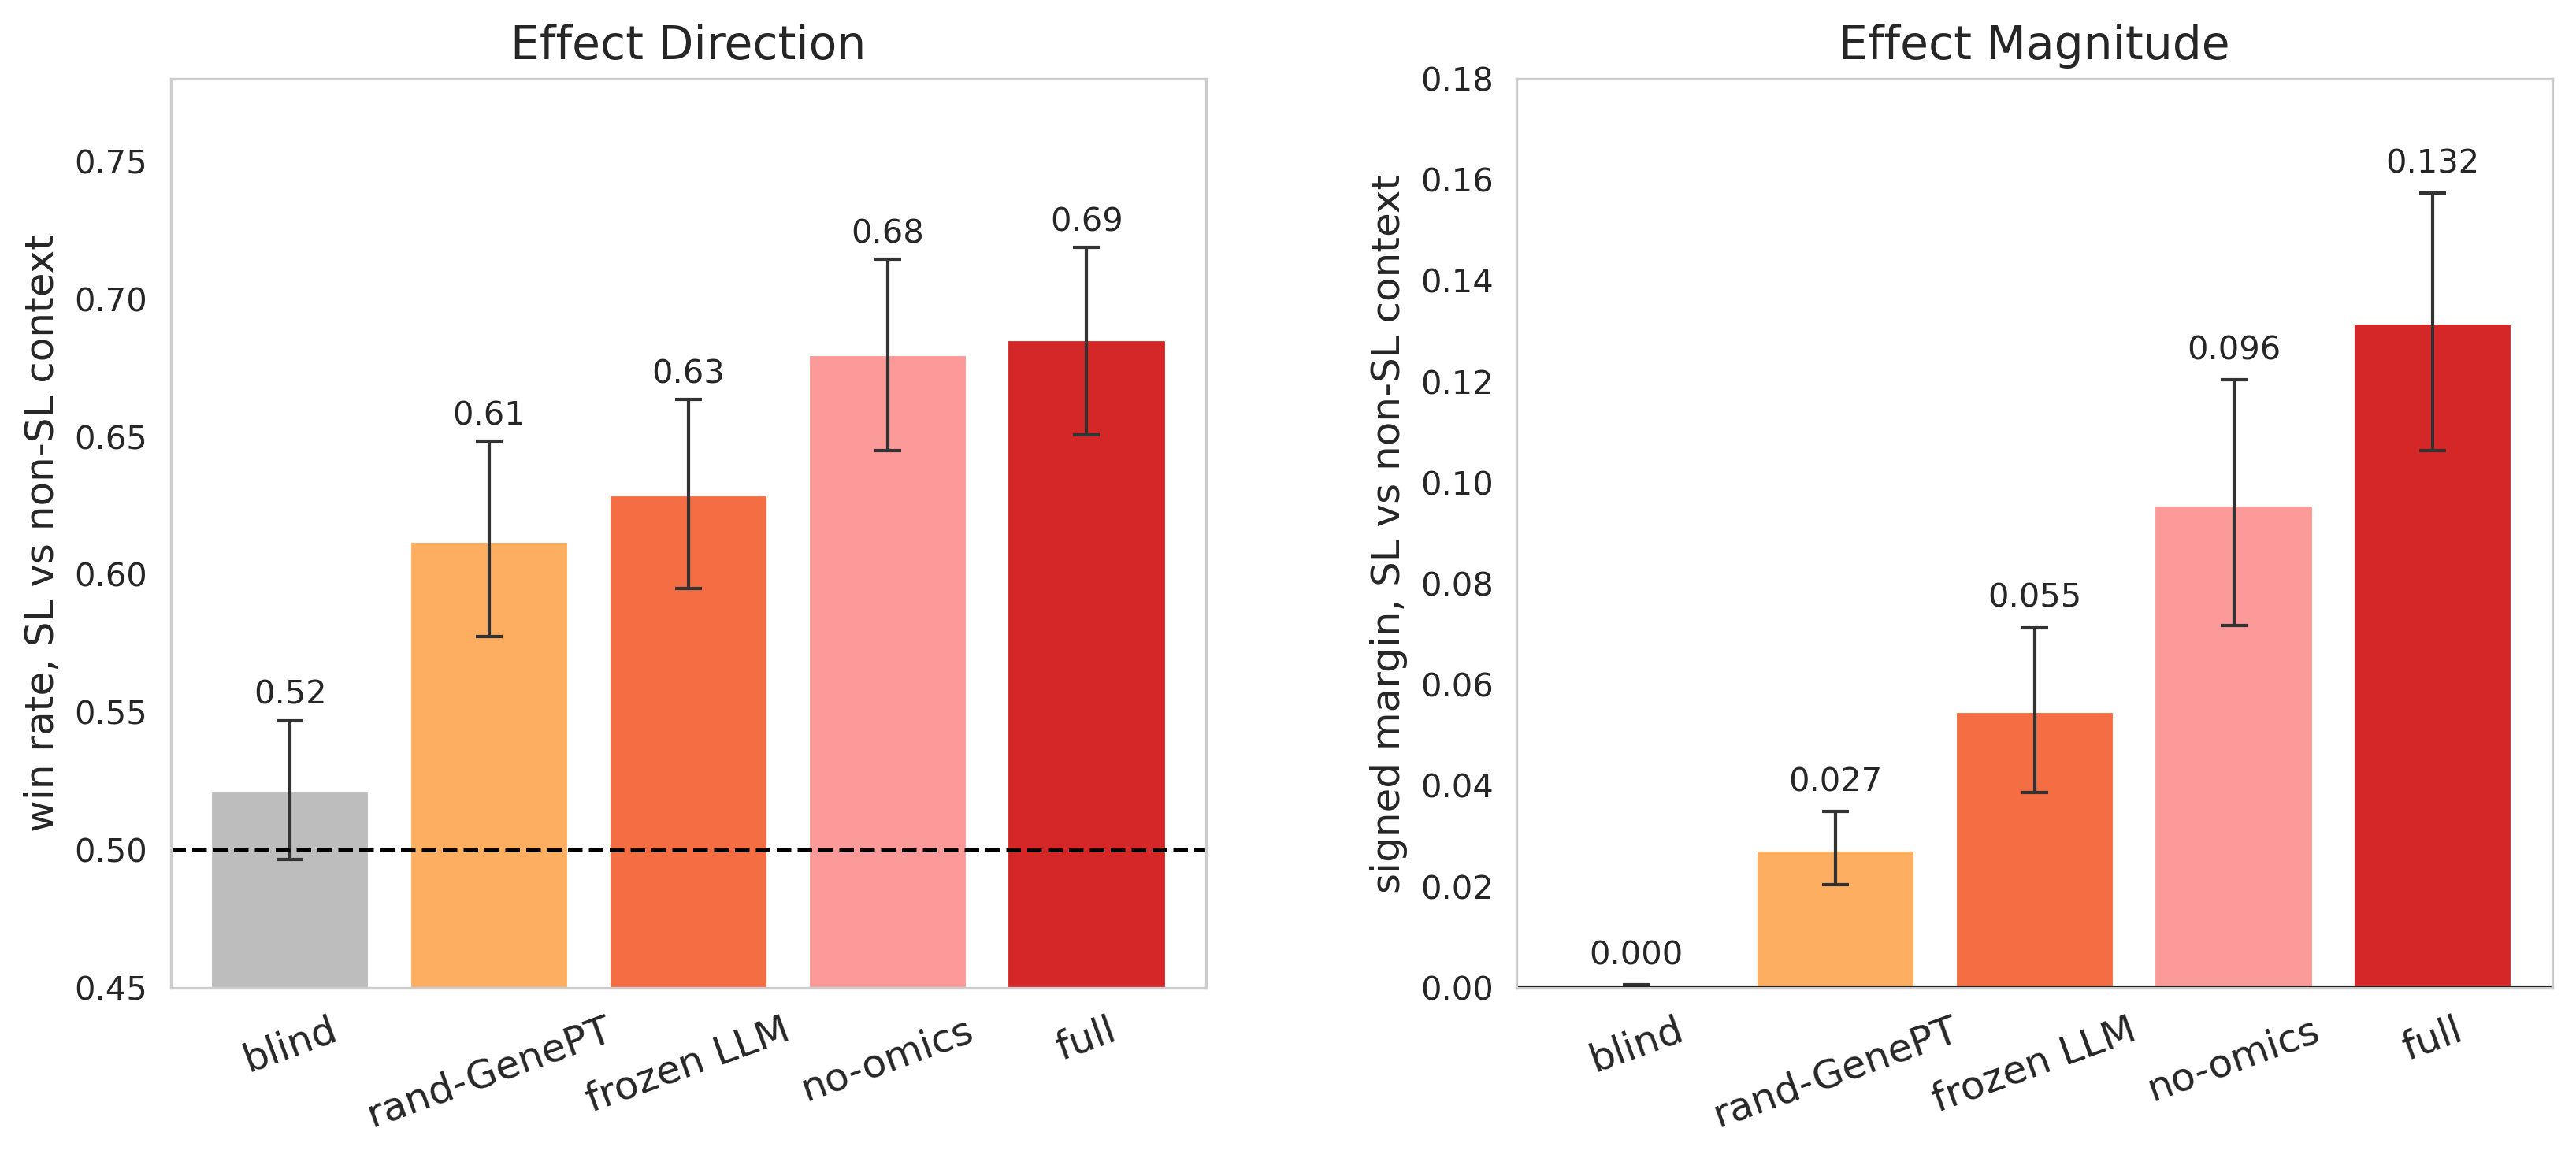

Route A (GPLO, n=581):
  blind          win=0.522  margin=+0.000
  rand-GenePT    win=0.612  margin=+0.027
  frozen LLM     win=0.629  margin=+0.055
  no-omics       win=0.680  margin=+0.096
  full           win=0.685  margin=+0.132


In [ ]:

order2 = ['A1', 'C1', 'D1', 'B1', 'full']
rng = np.random.default_rng(0); bidx = rng.integers(0, GN, size=(5000, GN))

# knobs
FIG_W, FIG_H = 11, 5     # figure size; keep FIG_H, reduce FIG_W to narrow the two subplots
WSPACE   = 0.3          # spacing between the two subplots (larger = farther)
BAR_STEP = 0.9           # in-subplot bar spacing (smaller = closer)
BAR_W    = 0.72          # bar width (must stay below BAR_STEP)
# ────────────────────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H),dpi=300)
x = np.arange(len(order2)) * BAR_STEP
XPAD = 0.6 * BAR_STEP    # side padding, scaled with the bar spacing

# (a) RANK win-rate (saturates), 95% CI
ax = axes[0]
for xi, k in zip(x, order2):
    wc = GWIN[k]; bs = wc[bidx].mean(1); lo, hi = np.percentile(bs, [2.5, 97.5])
    ax.bar(xi, wc.mean(), BAR_W, color=COL[k], yerr=[[wc.mean() - lo], [hi - wc.mean()]],
           capsize=4, error_kw=dict(lw=1, ecolor='#333'))
    ax.text(xi, hi + 0.006, f'{wc.mean():.2f}', ha='center', fontsize=10)
ax.grid(False)
ax.axhline(0.5, color='k', ls='--', lw=1.2); ax.text(x[-1] + XPAD, 0.508, '', ha='right', fontsize=10)
ax.set_ylim(0.45, 0.78); ax.set_xlim(x[0] - XPAD, x[-1] + XPAD); ax.set_xticks(x)
ax.set_xticklabels([LAB[k] for k in order2], rotation=20, fontsize=12)
ax.set_title('Effect Direction', fontsize=14)
ax.set_ylabel('win rate, SL vs non-SL context', fontsize=12)



# (b) EFFECT MAGNITUDE — within-pair signed margin
ax = axes[1]
for xi, k in zip(x, order2):
    m = GMARG[k]; bs = m[bidx].mean(1); lo, hi = np.percentile(bs, [2.5, 97.5])
    ax.bar(xi, m.mean(), BAR_W, color=COL[k], yerr=[[m.mean() - lo], [hi - m.mean()]],
           capsize=4, error_kw=dict(lw=1, ecolor='#333'))
    ax.text(xi, hi + 0.004, f'{m.mean():.3f}', ha='center', fontsize=10)
ax.grid(False)
ax.axhline(0, color='k', lw=1)
ax.set_xlim(x[0] - XPAD, x[-1] + XPAD); ax.set_xticks(x)
ax.set_xticklabels([LAB[k] for k in order2], rotation=20, fontsize=12)
ax.set_ylim(0, 0.18)
ax.set_title('Effect Magnitude', fontsize=14)
ax.set_ylabel('signed margin, SL vs non-SL context', fontsize=12)

plt.tight_layout()
fig.subplots_adjust(wspace=WSPACE)  # apply after tight_layout so it sticks
plt.show()
print(f'Route A (GPLO, n={GN}):')
for k in order2:
    print(f'  {LAB[k].replace(chr(10), " "):14s} win={GWIN[k].mean():.3f}  margin={GMARG[k].mean():+.3f}')

### Figure 2 (cases) - Conflict pairs 


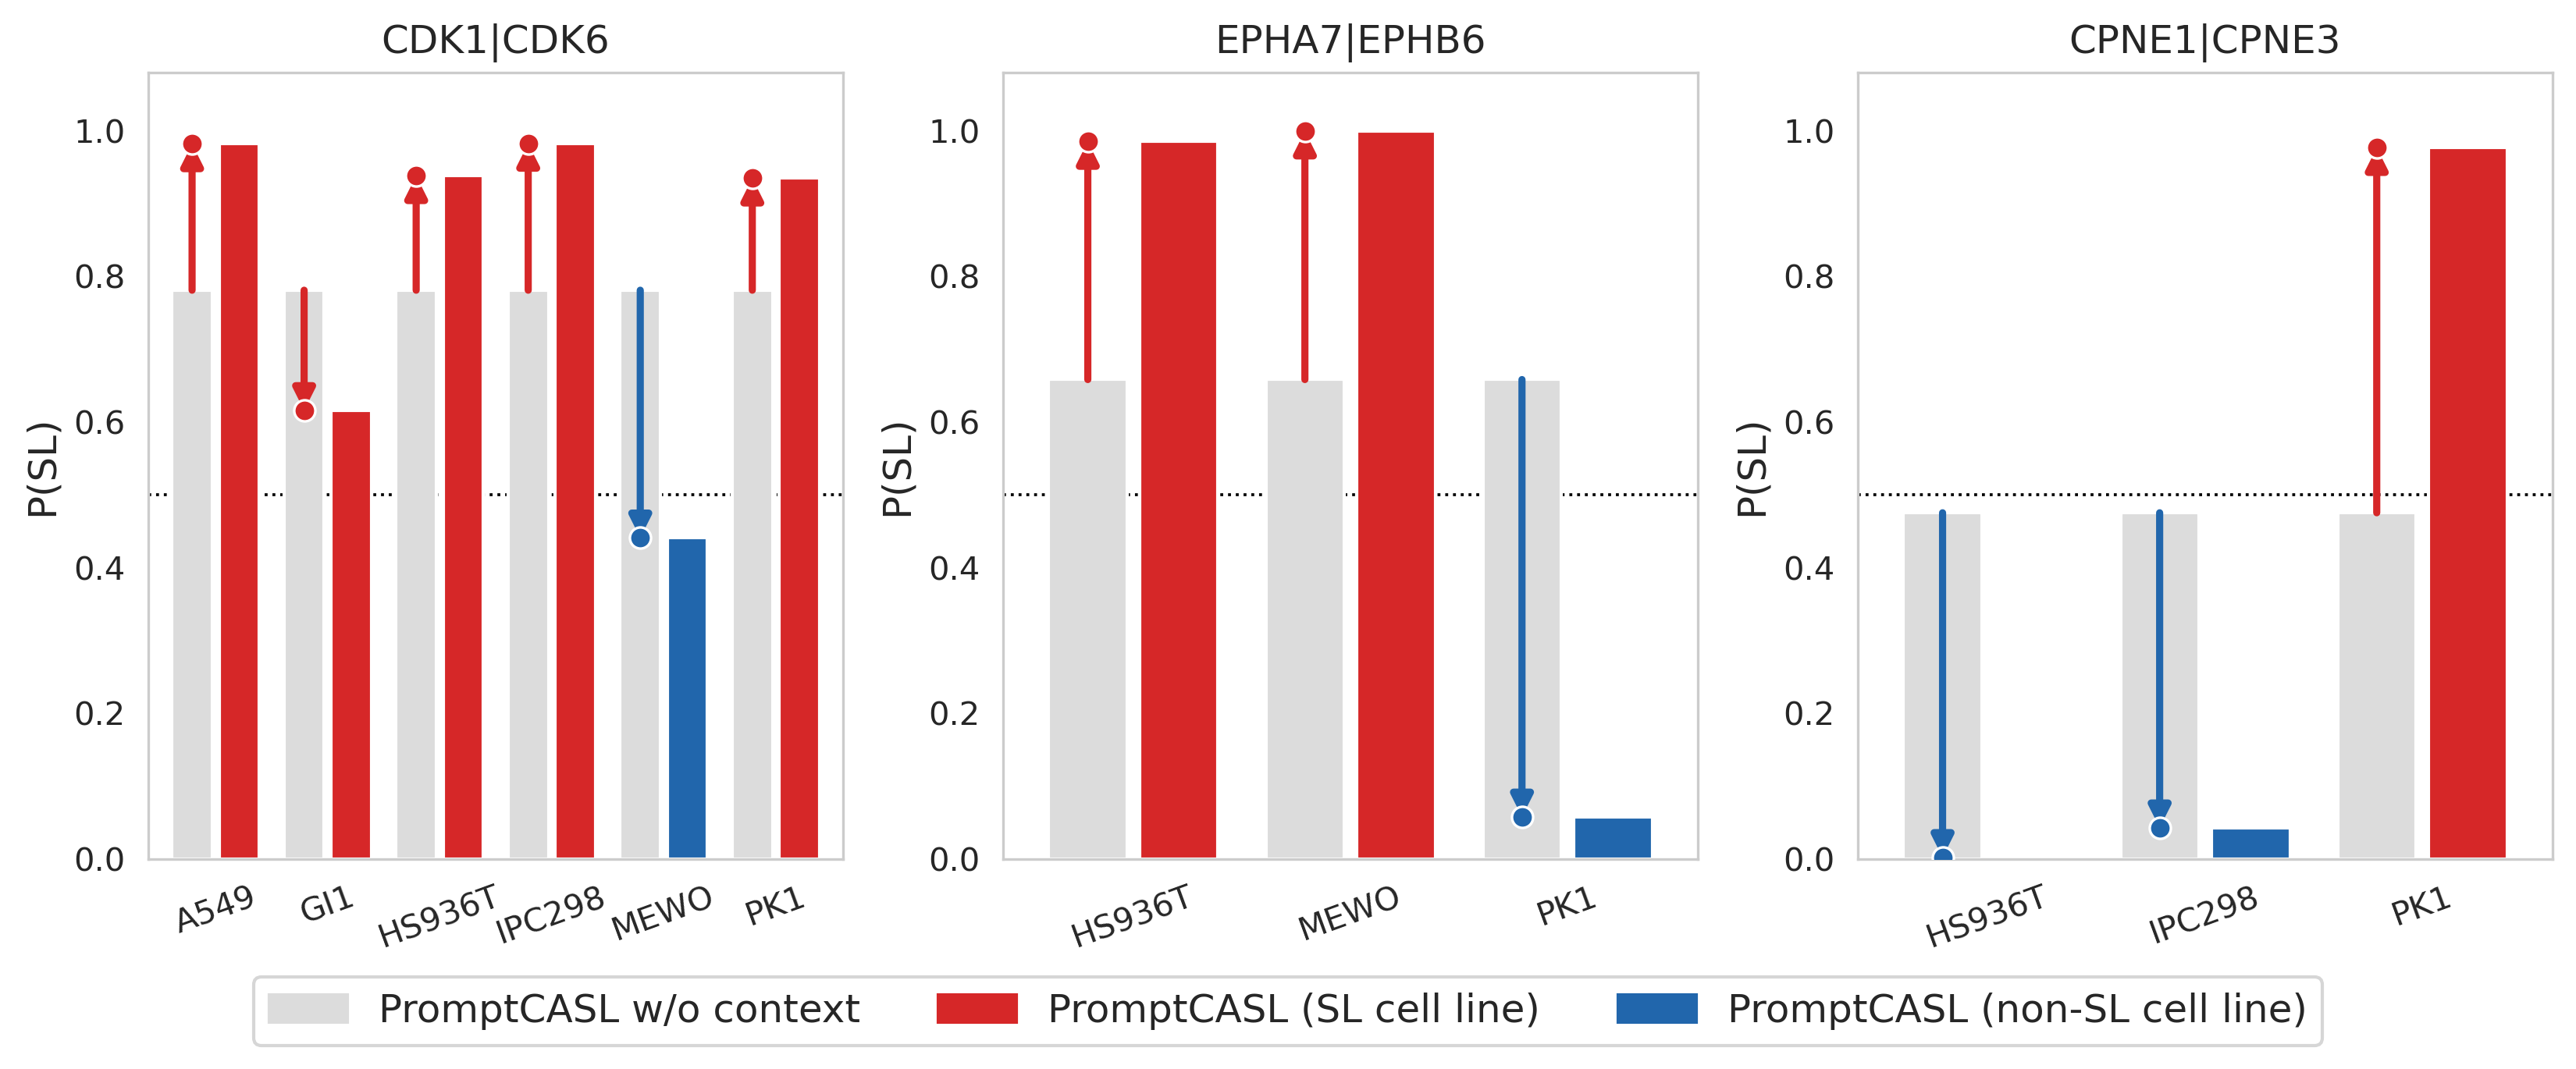

  CDK1|CDK6    [many-context] GPLO 6/6 correct · blind~0.78
  EPHA7|EPHB6  [clean-lineage] GPLO 3/3 correct · blind~0.66
  CPNE1|CPNE3  [strong-causal] GPLO 3/3 correct · blind~0.48


In [ ]:
import os, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.patches as mpatches
sys.path.insert(0, os.path.join(BASE, 'ana')); import model_version as MV
_pk = lambda g: '|'.join(sorted(str(g).split('|')))
def _ld(p):
    d = pd.read_csv(p); d['pk'] = d.gene_pair.map(_pk); return d
FULLf = _ld(MV.PRED_GPLO); BLINDf = _ld(MV.PRED_BLIND_GPLO)   # GPLO full (+context) vs no-context (A1 blind)
def pcl(df, pk): return df[df.pk == pk].groupby('cell_line').agg(prob=('prob', 'mean'), label=('label', 'first'))
def blindv(df, pk): return df[df.pk == pk].groupby('cell_line').prob.mean()
LN = {'A549': 'lung', 'PK1': 'panc', 'IPC298': 'mel', 'MEWO': 'mel', 'GI1': 'GBM', 'HS936T': 'mel'}

# 3 representative cases (one per type)
CLEAN = {
 'CDK1|CDK6':   ('cyclin-dependent kinases',         'many-context'),
 'EPHA7|EPHB6': ('Eph receptors (mel-SL vs panc)',   'clean-lineage'),
 'CPNE1|CPNE3': ('copines (Ca2+ membrane proteins)', 'strong-causal'),
}
pairs = list(CLEAN)
SHOW_FAMILY = False   # switch: family-name subtitle on (True) / off (False)

BAR_W, PAIR_GAP, CTX_STEP = 0.36, 0.06, 1.00
PANEL_W, PANEL_H = 3.7, 4.6
ARROW_LW, ARROW_HEAD, DOT_MS = 2.2, 13, 6.5
GREY, SLc, NSc = '#dcdcdc', '#d62728', '#2166ac'
off = (BAR_W + PAIR_GAP) / 2.0

fig, axes = plt.subplots(1, len(pairs), figsize=(PANEL_W * len(pairs), PANEL_H),dpi=300)
axes = np.atleast_1d(axes).ravel()
for ax, pk in zip(axes, pairs):
    f = pcl(FULLf, pk); b = blindv(BLINDf, pk); cls = list(f.index)
    for i, c in enumerate(cls):
        x = i * CTX_STEP
        bl = float(b.get(c, np.nan)); fu = float(f.loc[c, 'prob'])
        col = SLc if int(f.loc[c, 'label']) == 1 else NSc
        ax.bar(x - off, bl, BAR_W, color=GREY, zorder=2)                  # light grey = no-context
        ax.bar(x + off, fu, BAR_W, color=col, zorder=2)                   # coloured = full (+context)
        ax.annotate('', xy=(x - off, fu), xytext=(x - off, bl),
                    arrowprops=dict(arrowstyle='-|>', color=col, lw=ARROW_LW,
                                    mutation_scale=ARROW_HEAD, shrinkA=0, shrinkB=0), zorder=5)
        ax.plot([x - off], [fu], 'o', color=col, ms=DOT_MS, mec='white', mew=0.8, zorder=6)
    ax.grid(False)
    ax.axhline(0.5, color='k', ls=':', lw=.9, zorder=1)
    ax.set_xticks([i * CTX_STEP for i in range(len(cls))])
    ax.set_xticklabels(cls, fontsize=10,rotation=20)
    ax.set_ylim(0, 1.08); ax.set_xlim(-0.6 * CTX_STEP, (len(cls) - 1) * CTX_STEP + 0.6 * CTX_STEP)
    ax.set_ylabel('P(SL)', fontsize=12)
    nc = int((((f.label == 1) & (f.prob > .5)) | ((f.label == 0) & (f.prob < .5))).sum())
    fam, grp = CLEAN[pk]
    ax.set_title(f"{pk}\n{fam}" if SHOW_FAMILY else f"{pk}", fontsize=12) # fontweight='bold'
fig.legend(handles=[mpatches.Patch(color=GREY, label='PromptCASL w/o context'),
                    mpatches.Patch(color=SLc, label='PromptCASL (SL cell line)'),
                    mpatches.Patch(color=NSc, label='PromptCASL (non-SL cell line)')],
           loc='lower center', ncol=3, fontsize=12, bbox_to_anchor=(0.5, -0.03))
#              'left grey bar = no-context blind; right coloured bar = +context; '
plt.tight_layout(rect=[0, 0.04, 1, 0.97]); plt.show()

for pk in pairs:
    f = pcl(FULLf, pk); b = blindv(BLINDf, pk); fam, grp = CLEAN[pk]
    nc = int((((f.label == 1) & (f.prob > .5)) | ((f.label == 0) & (f.prob < .5))).sum())
    print(f"  {pk:12s} [{grp:12s}] GPLO {nc}/{len(f)} correct · blind~{b.mean():.2f}")

## Figure 3 - Retrieval attribution: attention budget & per-token enrichment

Gene-query cross-attention over the fused context memory. (a) attention-budget split between the text block and the pair-conditioned pathway block; (b) per-token enrichment by context category (1.0 = a typical valid token).


In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ATTN_N, ATTN_MEANVALID = 6662, 163
CAT_ORDER = ['cell-line name', 'tissue / lineage', 'cell-line prose', 'gene name',
             'expression phrase', 'copy-number phrase', 'mutation status', 'gene prose',
             '[CLS]/[SEP]', 'pathway evidence']
# per-token enrichment (1.0 = avg valid token); rows = geneA / geneB / mean
ENR = pd.DataFrame(
    [[0.82, 0.79, 0.74, 0.72, 0.79, 0.84, 0.69, 0.71, 0.68, 5.5],   # geneA query
     [0.82, 0.79, 0.74, 0.72, 0.79, 0.85, 0.70, 0.72, 0.68, 5.4],   # geneB query
     [0.82, 0.79, 0.74, 0.72, 0.79, 0.85, 0.70, 0.72, 0.68, 5.5]],  # mean
    index=['geneA query', 'geneB query', 'mean'], columns=CAT_ORDER)
# attention-budget block split (mass share)
BLOCK = {'text': 0.73, 'pathway': 0.27, 'n_text': 152, 'n_path': 8}
ENR.round(2)

,cell-line name,tissue / lineage,cell-line prose,gene name,expression phrase,copy-number phrase,mutation status,gene prose,[CLS]/[SEP],pathway evidence
geneA query,0.82,0.79,0.74,0.72,0.79,0.84,0.69,0.71,0.68,5.5
geneB query,0.82,0.79,0.74,0.72,0.79,0.85,0.70,0.72,0.68,5.4
mean,0.82,0.79,0.74,0.72,0.79,0.85,0.70,0.72,0.68,5.5


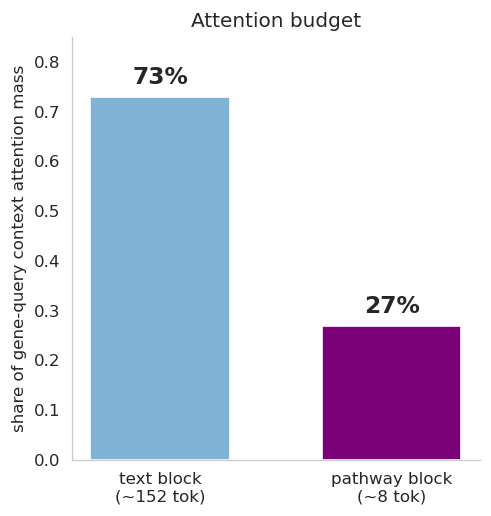

In [17]:
# Figure 3a - attention budget: text block vs pair-conditioned pathway block.
fig, ax = plt.subplots(figsize=(4.2, 4.4))
vals = [BLOCK['text'], BLOCK['pathway']]
ax.bar([0, 1], vals, color=['#7fb3d5', '#7a0177'], width=0.6, edgecolor='white')
for x, v in zip([0, 1], vals):
    ax.text(x, v + 0.015, f'{v*100:.0f}%', ha='center', va='bottom', fontsize=14, fontweight='bold')
ax.set_xticks([0, 1])
ax.set_xticklabels([f"text block\n(~{BLOCK['n_text']} tok)", f"pathway block\n(~{BLOCK['n_path']} tok)"])
ax.set_ylabel('share of gene-query context attention mass')
ax.set_ylim(0, 0.85)
ax.set_title('Attention budget', fontsize=12)
ax.grid(False)
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

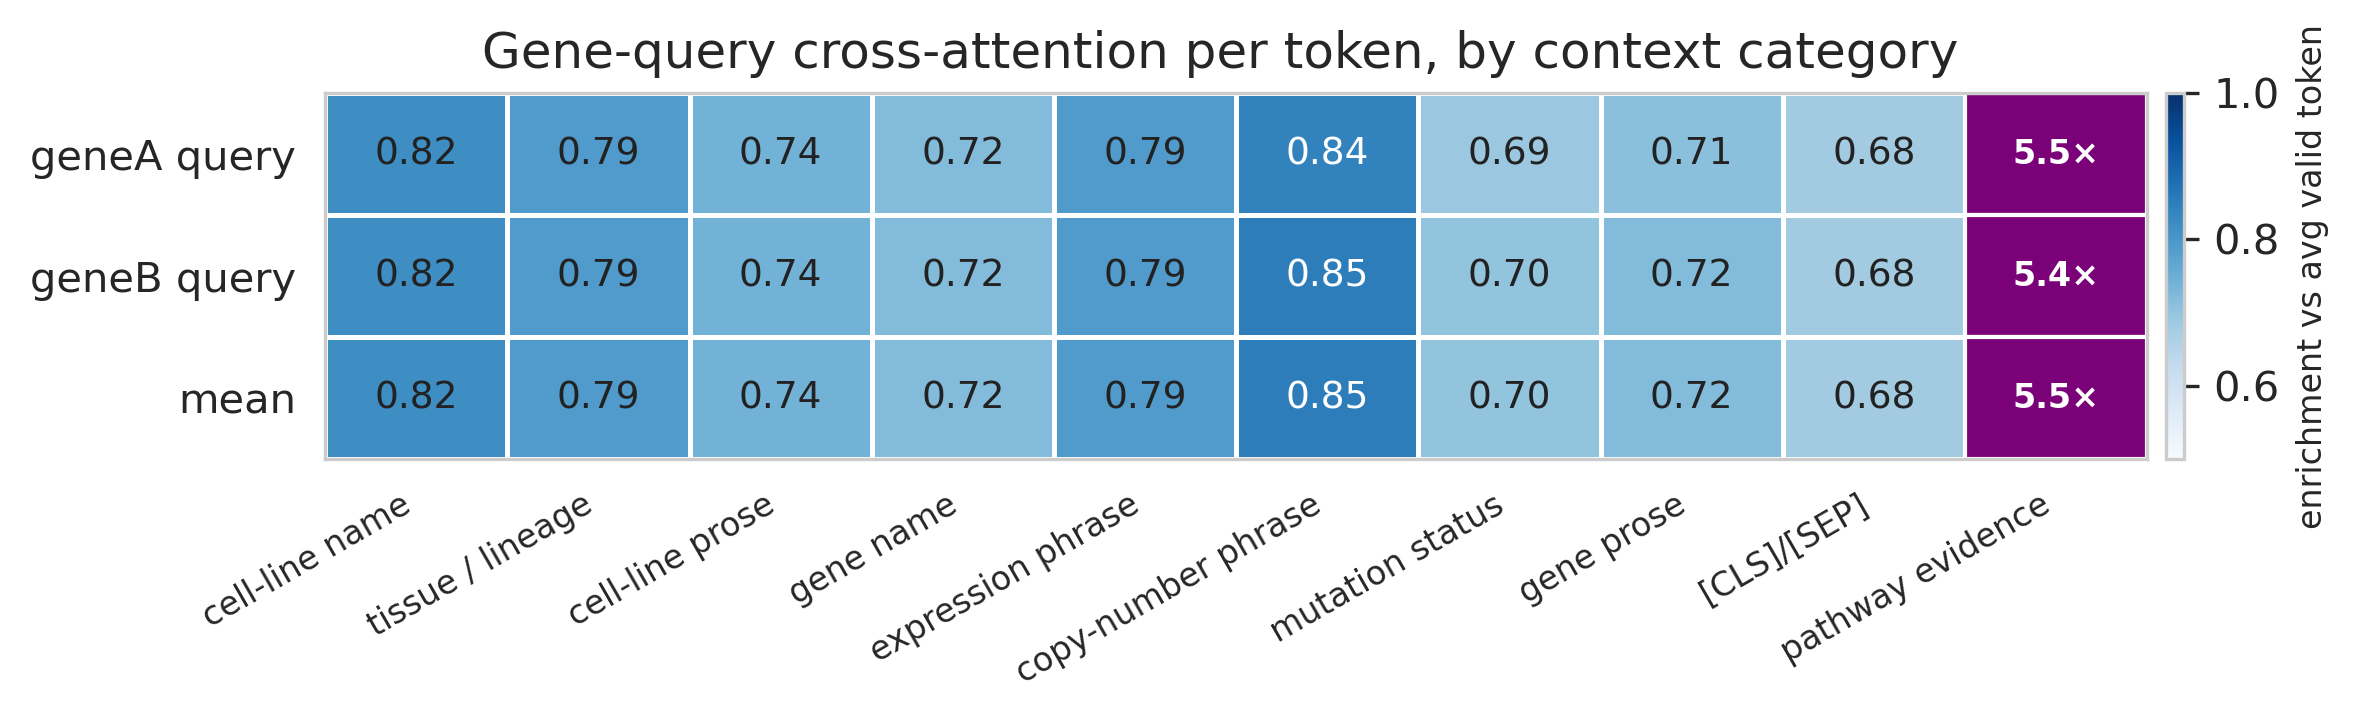

In [18]:
# Figure 3b - per-token gene-query attention enrichment by category (1.0 = avg valid token).


M = ENR.to_numpy(dtype=float)
jp = CAT_ORDER.index('pathway evidence')
Mtext = M.copy(); Mtext[:, jp] = np.nan          # pathway drawn separately (off the 0.5-1.0 scale)

fig, ax = plt.subplots(figsize=(8, 2.5), dpi=300)
im = ax.imshow(np.ma.masked_invalid(Mtext), cmap='Blues', vmin=0.5, vmax=1.0, aspect='auto')
for i in range(3):                                # pathway column: distinct colour + Nx label
    ax.add_patch(plt.Rectangle((jp - 0.5, i - 0.5), 1, 1, facecolor='#7a0177', edgecolor='white'))
    ax.text(jp, i, f'{M[i, jp]:.1f}×', ha='center', va='center',
            color='white', fontsize=8, fontweight='bold')
for i in range(3):                                # text-cell annotations
    for j in range(len(CAT_ORDER)):
        if j == jp:
            continue
        v = M[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center',
                color='white' if v > 0.82 else '#222222', fontsize=9)
ax.set_xticks(range(len(CAT_ORDER))); ax.set_xticklabels(CAT_ORDER, rotation=30, ha='right', fontsize=8)
ax.set_yticks([0, 1, 2]); ax.set_yticklabels(ENR.index)
ax.set_xticks(np.arange(-.5, len(CAT_ORDER), 1), minor=True)
ax.set_yticks(np.arange(-.5, 3, 1), minor=True)
ax.grid(which='minor', color='white', linewidth=1.2); 
ax.grid(which='major', visible=False)  
ax.tick_params(which='minor', length=0)
cb = fig.colorbar(im, ax=ax, fraction=0.018, pad=0.01)
cb.set_label('enrichment vs avg valid token', fontsize=8)
ax.set_title('Gene-query cross-attention per token, by context category  ',

             fontsize=12)
plt.tight_layout(); plt.show()